# CO₂ emissions — 01: Data cleaning

**Dataset:** Our World in Data, *CO₂ and Greenhouse Gas Emissions* (https://github.com/owid/co2-data)

**Input:** `data/raw/owid-co2-data.csv` (column definitions in `data/raw/owid-co2-codebook.csv`)

**Output:** `data/clean/co2_clean.csv`, read by `02_analysis.ipynb`

This notebook does the data preparation: a first look at the structure, a focused column subset,
separation of real countries from aggregates, and a check of missingness. The analysis itself is in
`02_analysis.ipynb`.

Emissions are in million tonnes of CO₂ (Mt) in the raw data.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ---- chart style (one palette for the whole notebook) ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
# ---- project paths (work whether the kernel starts in co2-eda/ or co2-eda/notebooks/) ----
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
RAW, CLEAN, FIG = ROOT / "data" / "raw", ROOT / "data" / "clean", ROOT / "figures"
for p in (CLEAN, FIG):
    p.mkdir(parents=True, exist_ok=True)

def save(name):
    """Save the current figure to figures/ (ready to paste into slides) and show it."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## 1. First look at the data

Load the file, then answer the basic questions: how big is it, what does one row mean, what is missing?

In [2]:
URL = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
LOCAL = RAW / "owid-co2-data.csv"          # downloaded copy in data/raw/
df = pd.read_csv(LOCAL if LOCAL.exists() else URL)

print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Years: {df.year.min()} to {df.year.max()}   Distinct 'country' values: {df.country.nunique()}")
df.sample(5, random_state=1).iloc[:, :10]

Rows: 56,269   Columns: 79
Years: 1750 to 2025   Distinct 'country' values: 259


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct
34547,Mozambique,1961,MOZ,6834938.0,1.625451e+10,0.105394,0.01542,2.560274,0.707181,38.162197
54946,Vietnam,1882,VNM,10875064.0,NaN,0.000000,0.00000,NaN,NaN,NaN
600,Africa (GCP),1898,NaN,NaN,NaN,NaN,NaN,6.049264,NaN,NaN
32495,Mayotte,1872,MYT,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
52933,United Kingdom,1781,GBR,NaN,NaN,NaN,NaN,16.234383,0.355657,2.239835


One row is **one location in one year**. Most of the 79 columns are variants of the same few measures (per capita, per GDP, cumulative, share of global), so we keep a focused subset.

**The only preparation we do** (three small steps, no heavy cleaning):

1. keep the columns we need;
2. split real countries from aggregates such as *World*, *Asia* or *High-income countries*, which would otherwise be double counted;
3. add GDP per capita.

In [3]:
COLS = ["country", "year", "iso_code", "population", "gdp",
        "co2", "co2_per_capita", "cumulative_co2", "share_global_co2", "share_global_cumulative_co2",
        "coal_co2", "oil_co2", "gas_co2", "cement_co2", "flaring_co2", "other_industry_co2",
        "consumption_co2", "trade_co2", "trade_co2_share", "co2_per_gdp", "energy_per_capita"]
data = df[COLS].copy()
data["gdp_per_capita"] = data["gdp"] / data["population"]

is_aggregate = data["iso_code"].isna() | data["iso_code"].astype(str).str.startswith("OWID")
countries = data[~is_aggregate]
aggregates = data[is_aggregate]
world = aggregates[aggregates.country == "World"].set_index("year")

YEAR = 2024       # latest year with complete data (2025 values are preliminary)
GDP_YEAR = 2022   # GDP is only available up to 2022
latest = countries[countries.year == YEAR]

print(f"{countries.country.nunique()} countries, {aggregates.country.nunique()} aggregates")
countries[["population", "gdp_per_capita", "co2", "co2_per_capita", "cumulative_co2"]].describe().T.round(2)

223 countries, 36 aggregates


,count,mean,std,min,25%,50%,75%,max
population,41276.0,14889842.10,71234794.61,21.00,294485.75,1989930.00,7126421.25,1.463866e+09
gdp_per_capita,15315.0,8564.63,11835.10,361.19,1848.09,4050.24,9878.74,1.635314e+05
co2,24109.0,76.30,441.10,0.00,0.24,2.60,21.82,1.241749e+04
co2_per_capita,23599.0,4.10,20.10,0.00,0.17,1.02,4.35,1.062530e+03
cumulative_co2,24109.0,2928.11,18033.62,0.00,3.17,48.63,551.25,4.393433e+05


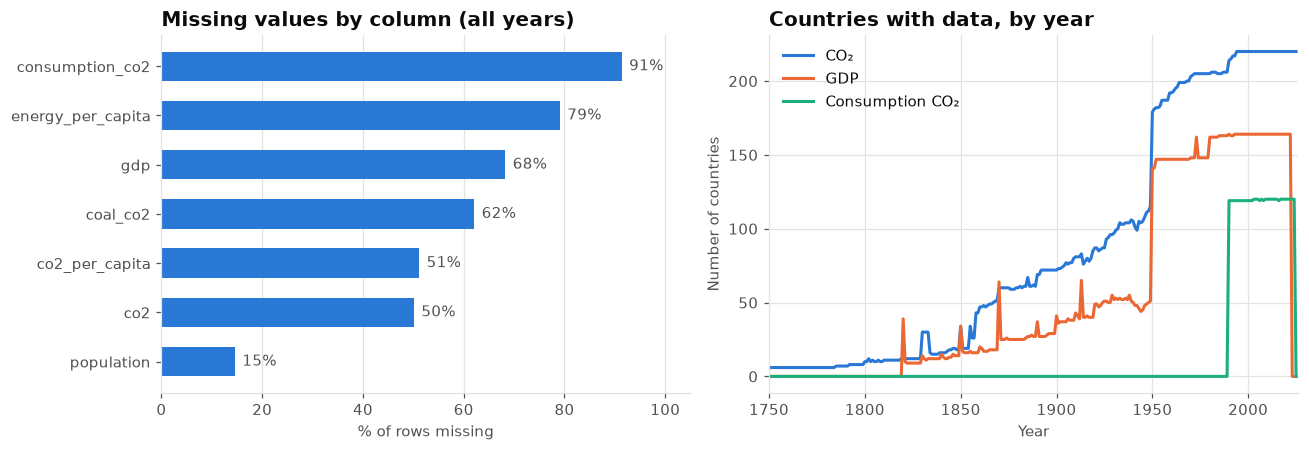

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))

miss = countries[["co2", "co2_per_capita", "population", "gdp", "coal_co2", "energy_per_capita",
                  "consumption_co2"]].isna().mean().mul(100).sort_values()
a.barh(miss.index, miss.values, color=BLUE, height=0.6)
for y, v in enumerate(miss.values):
    a.text(v + 1.5, y, f"{v:.0f}%", va="center", color=MUTED)
a.set(title="Missing values by column (all years)", xlabel="% of rows missing", xlim=(0, 105))
a.grid(axis="y", visible=False)

cov = countries.groupby("year")[["co2", "gdp", "consumption_co2"]].count()
for col, c, lab in [("co2", BLUE, "CO₂"), ("gdp", ORANGE, "GDP"), ("consumption_co2", AQUA, "Consumption CO₂")]:
    b.plot(cov.index, cov[col], color=c, label=lab)
b.set(title="Countries with data, by year", xlabel="Year", ylabel="Number of countries", xlim=(1750, 2026))
b.legend(loc="upper left")
save("01_missingness")

**What we learn**

- Missingness is **structural, not random**: it comes from history. Before 1950 fewer than half of the countries have CO₂ records, and coverage grows steadily after that.
- CO₂ data is nearly complete for recent decades (220 of 223 countries). GDP stops in 2022, and consumption-based emissions exist only from 1990 for about 120 countries.
- Consequence for the analysis: we do not fill anything in. We use the full history for global trends, and recent years for country comparisons.

## 2. Export the clean table

The clean file keeps every row (countries *and* aggregates) with an `is_aggregate` flag, so the analysis
notebook can split them without repeating the logic above.


In [5]:
clean = data.assign(is_aggregate=is_aggregate)
OUT = CLEAN / "co2_clean.csv"
clean.to_csv(OUT, index=False)
print(f"Wrote {OUT.relative_to(ROOT)}: {clean.shape[0]:,} rows, {clean.shape[1]} columns")
clean.head()


Wrote data/clean/co2_clean.csv: 56,269 rows, 23 columns


,country,year,iso_code,population,gdp,co2,co2_per_capita,cumulative_co2,share_global_co2,share_global_cumulative_co2,...,cement_co2,flaring_co2,other_industry_co2,consumption_co2,trade_co2,trade_co2_share,co2_per_gdp,energy_per_capita,gdp_per_capita,is_aggregate
0,Afghanistan,1750,AFG,2802560.0,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,Afghanistan,1751,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,Afghanistan,1752,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,Afghanistan,1753,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,Afghanistan,1754,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
